Mean Squared Error: 7774447.403
R-squared: 0.588


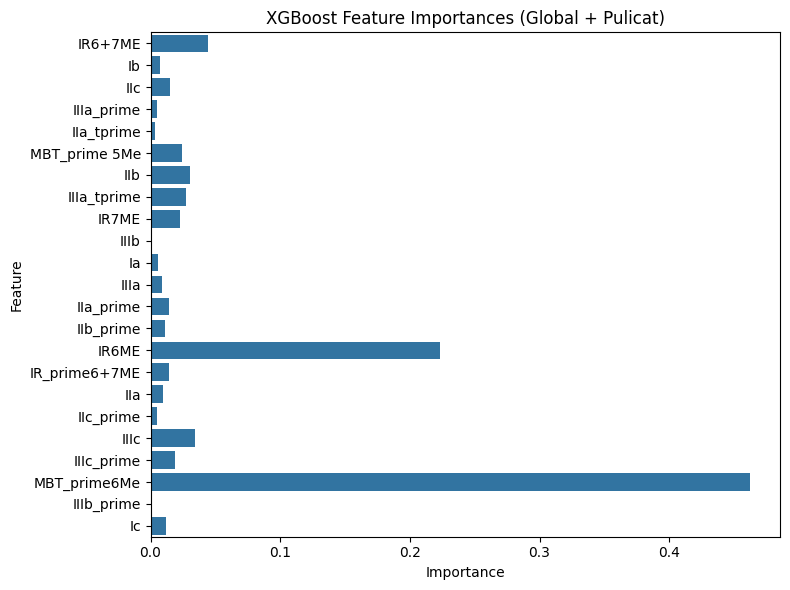

In [28]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
import seaborn as sns
import matplotlib.pyplot as plt

# --------------------------
# Load Pulicat dataset (regional)
# --------------------------
file_pulicat = "/Users/Dasgu004/Library/CloudStorage/OneDrive-UniversiteitUtrecht/PostDoc/Projects/CN/Pulicat_GDGT_python.xlsx"
df_pulicat = pd.read_excel(file_pulicat, sheet_name="Sheet1", header=1)
df_pulicat.columns = df_pulicat.columns.str.strip()

predictor_cols_pulicat = [
    "SALINITY(PPT)", "IIIa", "IIIa_prime", "IIIa_tprime", "IIIb", "IIIb_prime", "IIIc", "IIIc_prime",
    "IIa", "IIa_prime", "IIa_tprime", "IIb", "IIb_prime", "IIc", "IIc_prime",
    "Ia", "Ib", "Ic", "brGDGT conc. (ng/g)",
    "Archaeol", "GDGT0", "GDGT1", "GDGT2", "GDGT3", "CREN", "CREN_prime",
    "BIT", "CBT", "CBT_prime", "MBT_prime", "CBT 5Me",
    "IR6ME", "IR7ME", "IR_prime6+7ME", "IR6+7ME", "INDEX1", "MBT_prime 5Me", "MBT_prime6Me"
]

df_pulicat = df_pulicat[predictor_cols_pulicat].apply(pd.to_numeric, errors='coerce')
df_pulicat = df_pulicat.dropna(axis=0, how='any')

# Convert PPT → mg/L (approx: 1 ppt ≈ 1000 mg/L)
df_pulicat["SALINITY(mg/l)"] = df_pulicat["SALINITY(PPT)"] * 1000
df_pulicat = df_pulicat.drop(columns=["SALINITY(PPT)"])

# --------------------------
# Load Global dataset
# --------------------------
file_global = "/Users/Dasgu004/Library/CloudStorage/OneDrive-UniversiteitUtrecht/PostDoc/Projects/CN/Salinity_GDGT_Global.xlsx"
df_global = pd.read_excel(file_global, sheet_name="Sheet1", header=0)
df_global.columns = df_global.columns.str.strip()

predictor_cols_global = [
    "SALINITY(mg/l)",
    "IIIa", "IIIa_prime", "IIIa_tprime", "IIIb", "IIIb_prime", "IIIc", "IIIc_prime",
    "IIa", "IIa_prime", "IIa_tprime", "IIb", "IIb_prime", "IIc", "IIc_prime",
    "Ia", "Ib", "Ic",
    "IR6ME", "IR7ME", "IR_prime6+7ME", "IR6+7ME",
    "MBT_prime 5Me", "MBT_prime6Me",
    "ACE", "ACE_prime",
    "MLWT", "pH", "DO", "TN", "OM", "C/N"
]

df_global = df_global[predictor_cols_global].apply(pd.to_numeric, errors='coerce')
df_global = df_global.dropna(axis=0, how='any')

# --------------------------
# Merge datasets (align columns)
# --------------------------
common_cols = list(set(df_pulicat.columns) & set(df_global.columns))
df_combined = pd.concat([
    df_pulicat[common_cols],
    df_global[common_cols]
], ignore_index=True)

# --------------------------
# Define predictors & target
# --------------------------
y = df_combined["SALINITY(mg/l)"]
X = df_combined.drop(columns=["SALINITY(mg/l)"])

# --------------------------
# Train/Test Split
# --------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --------------------------
# XGBoost Model
# --------------------------
model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# --------------------------
# Evaluation
# --------------------------
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.3f}")
print(f"R-squared: {r2:.3f}")

# --------------------------
# Feature Importance
# --------------------------
plt.figure(figsize=(8, 6))
sns.barplot(x=model.feature_importances_, y=X.columns)
plt.title("XGBoost Feature Importances (Global + Pulicat)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [34]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

# ------------------------
# Load Global Dataset
# ------------------------
global_path = "/Users/Dasgu004/Library/CloudStorage/OneDrive-UniversiteitUtrecht/PostDoc/Projects/CN/Salinity_GDGT_Global.xlsx"
df_global = pd.read_excel(global_path, sheet_name="Sheet1", header=0)
df_global.columns = df_global.columns.str.strip()

global_predictor_cols = [
    "SALINITY(mg/l)",
    "IIIa", "IIIa_prime", "IIIa_tprime", "IIIb", "IIIb_prime", "IIIc", "IIIc_prime",
    "IIa", "IIa_prime", "IIa_tprime", "IIb", "IIb_prime", "IIc", "IIc_prime",
    "Ia", "Ib", "Ic",
    "IR6ME", "IR7ME", "IR_prime6+7ME", "IR6+7ME",
    "MBT_prime 5Me", "MBT_prime6Me",
    "ACE", "ACE_prime",
    "MLWT", "pH", "DO", "TN", "OM", "C/N"
]

df_global = df_global[global_predictor_cols].dropna()
y_global = df_global["SALINITY(mg/l)"]
X_global = df_global.drop(columns=["SALINITY(mg/l)"])

# ------------------------
# Load Pulicat Dataset
# ------------------------
pulicat_path = "/Users/Dasgu004/Library/CloudStorage/OneDrive-UniversiteitUtrecht/PostDoc/Projects/CN/Pulicat_GDGT_python.xlsx"
df_pulicat = pd.read_excel(pulicat_path, sheet_name="Sheet1", header=1)
df_pulicat.columns = df_pulicat.columns.str.strip()

pulicat_predictor_cols = [
    "SALINITY(PPT)", "IIIa", "IIIa_prime", "IIIa_tprime", "IIIb", "IIIb_prime", "IIIc", "IIIc_prime",
    "IIa", "IIa_prime", "IIa_tprime", "IIb", "IIb_prime", "IIc", "IIc_prime",
    "Ia", "Ib", "Ic", "brGDGT conc. (ng/g)",
    "Archaeol", "GDGT0", "GDGT1", "GDGT2", "GDGT3", "CREN", "CREN_prime",
    "BIT", "CBT", "CBT_prime", "MBT_prime", "CBT 5Me",
    "IR6ME", "IR7ME", "IR_prime6+7ME", "IR6+7ME", "INDEX1", "MBT_prime 5Me", "MBT_prime6Me"
]

# Match features with global (drop salinity & any extras not in global)
common_features = list(set(global_predictor_cols[1:]).intersection(set(pulicat_predictor_cols)))
df_pulicat = df_pulicat[["SALINITY(PPT)"] + common_features].dropna()
print(f"Pulicat dataset common features to both dataset: {df_pulicat.columns.tolist()}")

# Convert PPT to mg/L for comparison (1 ppt = 1000 mg/L)
y_pulicat = df_pulicat["SALINITY(PPT)"] * 1000
X_pulicat = df_pulicat.drop(columns=["SALINITY(PPT)"])

# Find common features (excluding salinity)
common_features = sorted(list(set(X_global.columns).intersection(set(X_pulicat.columns))))

# Subset and reorder columns
X_global_common = X_global[common_features]
X_pulicat_common = X_pulicat[common_features]

# Now scale
scaler = StandardScaler()
X_global_scaled = scaler.fit_transform(X_global_common)
X_pulicat_scaled = scaler.transform(X_pulicat_common)

# Then train model on global and predict on pulicat
model = XGBRegressor(
    n_estimators=800,
    learning_rate=0.01,
    max_depth=4,
    subsample=0.7,
    colsample_bytree=0.7,
    random_state=42
)

model.fit(X_global_scaled, y_global)

y_pred_pulicat = model.predict(X_pulicat_scaled)

mse = mean_squared_error(y_pulicat, y_pred_pulicat)
r2 = r2_score(y_pulicat, y_pred_pulicat)

print("Train: Global → Test: Pulicat")
print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.3f}")


Pulicat dataset common features to both dataset: ['SALINITY(PPT)', 'IR6+7ME', 'Ib', 'IIc', 'IIIa_prime', 'IIa_tprime', 'MBT_prime 5Me', 'IIb', 'IIIa_tprime', 'IR7ME', 'IIIb', 'Ia', 'IIIa', 'IIa_prime', 'IIb_prime', 'IR6ME', 'IR_prime6+7ME', 'IIa', 'IIc_prime', 'IIIc', 'IIIc_prime', 'MBT_prime6Me', 'IIIb_prime', 'Ic']
Train: Global → Test: Pulicat
Mean Squared Error: 20769800.95
R-squared: 0.280


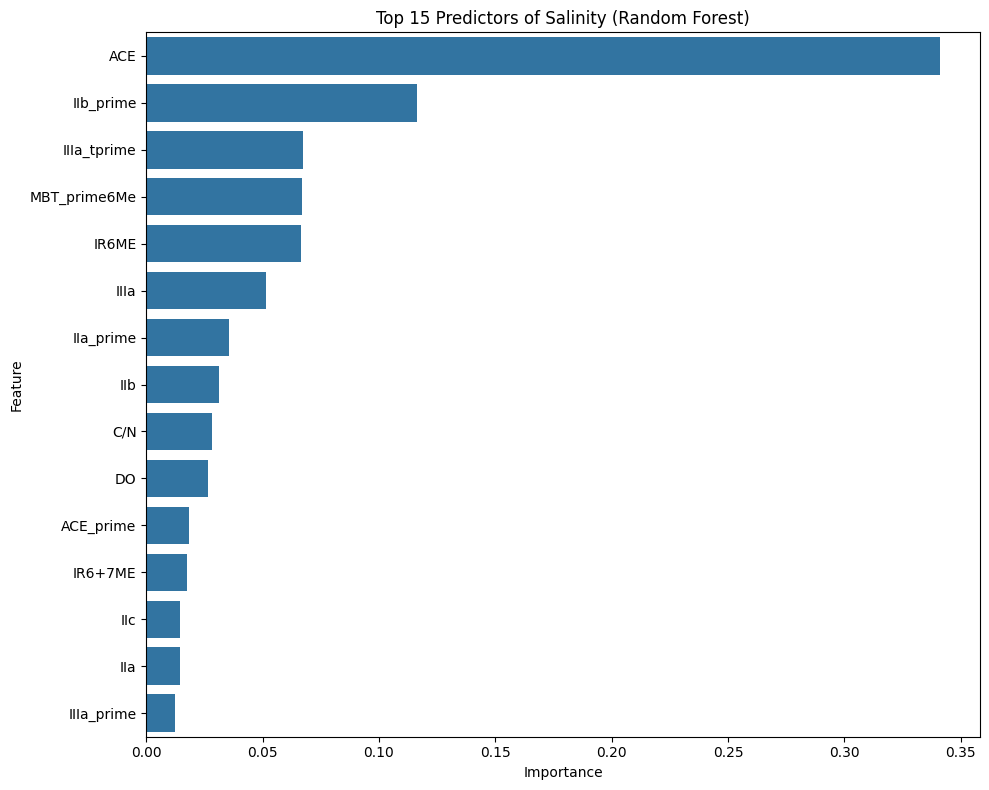

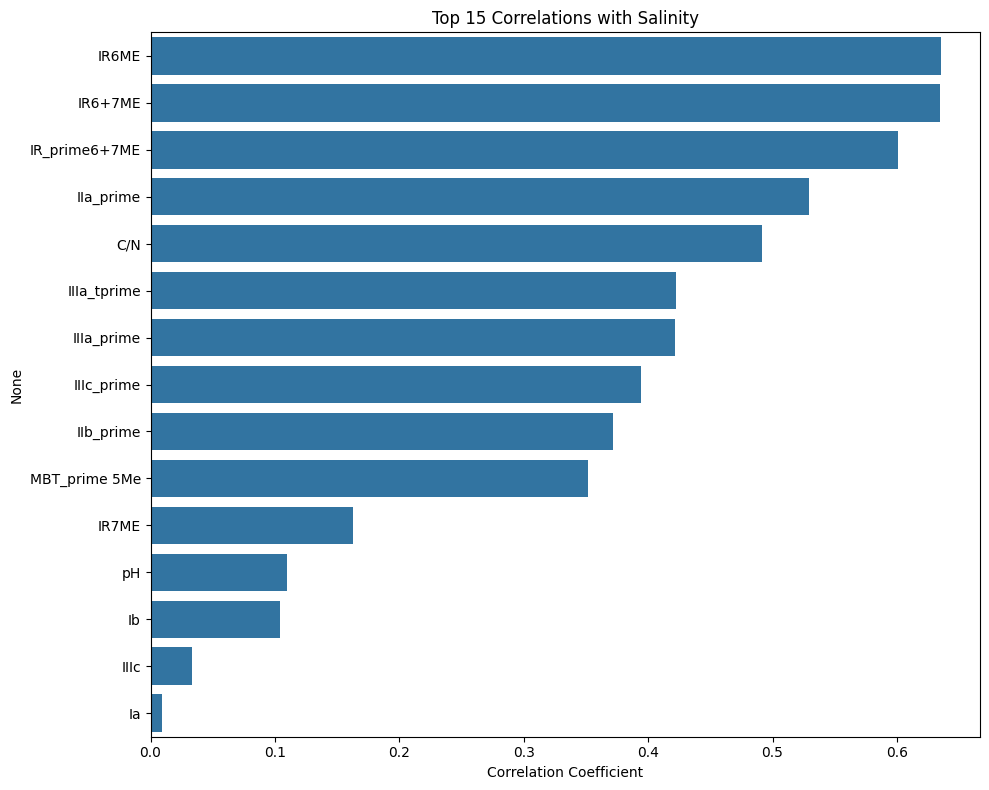

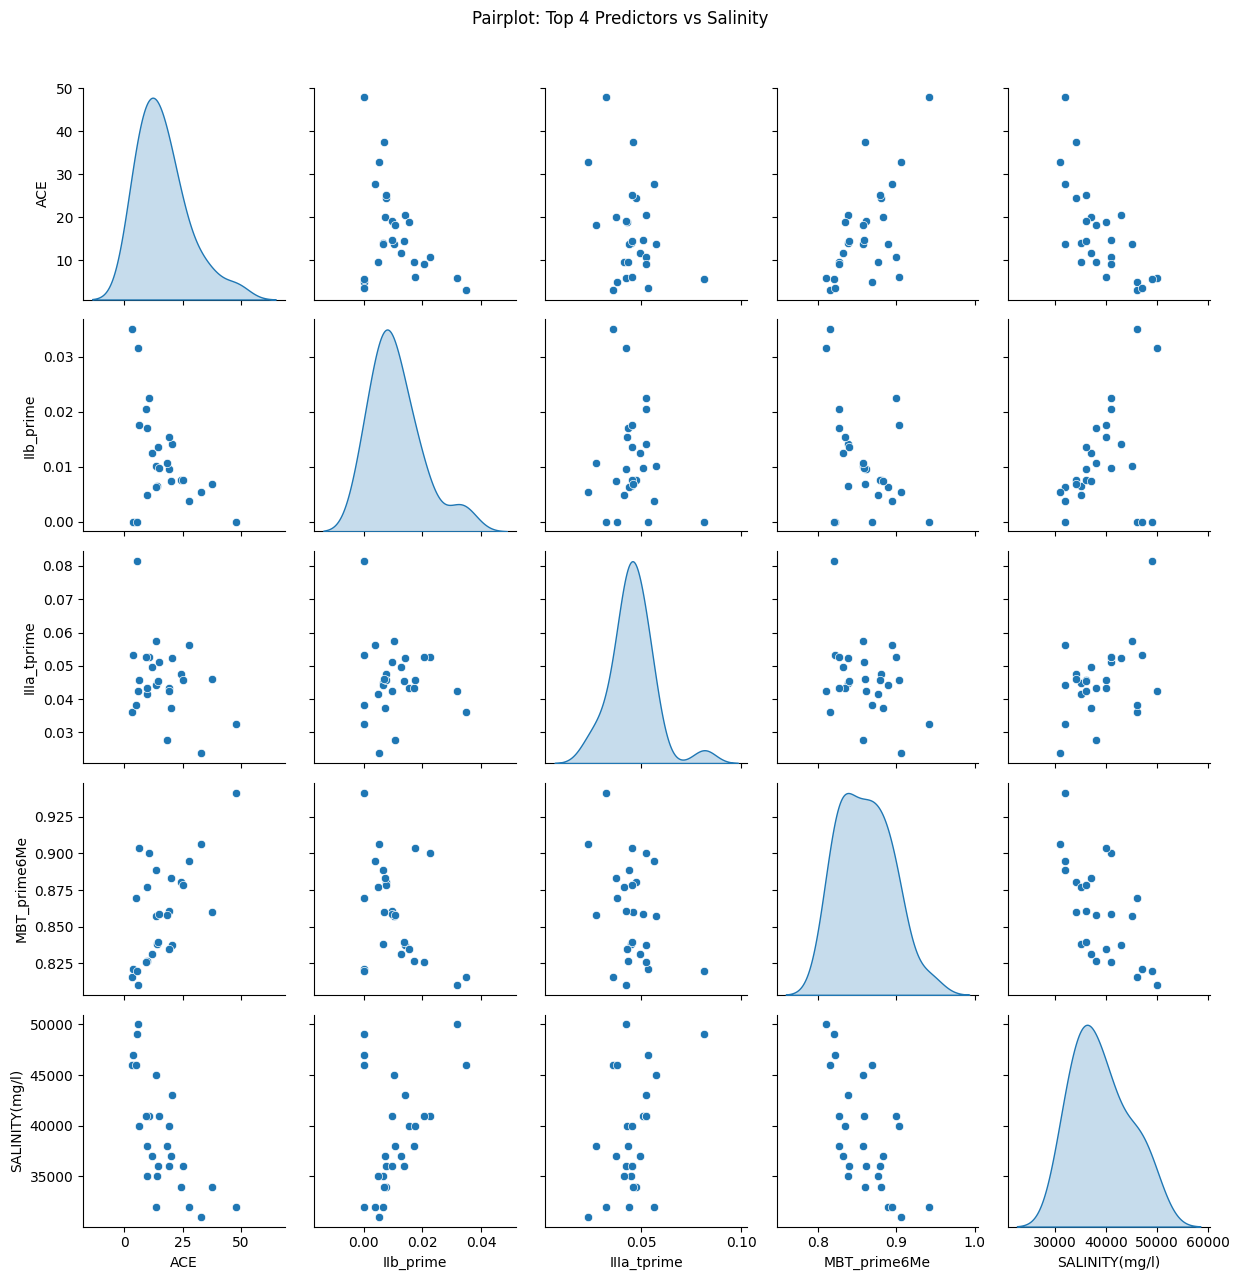

In [15]:
#Global

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler

# --------------------------
# Load Excel
# --------------------------
file_path = "/Users/Dasgu004/Library/CloudStorage/OneDrive-UniversiteitUtrecht/PostDoc/Projects/CN/Salinity_GDGT_Global.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1", header=0)

# Clean column names
df.columns = df.columns.str.strip()

# --------------------------
# Select fixed columns
# --------------------------
predictor_cols = [
    "SALINITY(mg/l)",
    "IIIa", "IIIa_prime", "IIIa_tprime", "IIIb", "IIIb_prime", "IIIc", "IIIc_prime",
    "IIa", "IIa_prime", "IIa_tprime", "IIb", "IIb_prime", "IIc", "IIc_prime",
    "Ia", "Ib", "Ic",
    "IR6ME", "IR7ME", "IR_prime6+7ME", "IR6+7ME",
    "MBT_prime 5Me", "MBT_prime6Me",
    "ACE", "ACE_prime",
    "MLWT", "pH", "DO", "TN", "OM", "C/N"
]

# Keep only those columns present in the dataframe
predictor_cols = [col for col in predictor_cols if col in df.columns]

# --------------------------
# Keep only numeric values & drop NaNs
# --------------------------
df = df[predictor_cols]
df = df.apply(pd.to_numeric, errors='coerce')  # convert non-numeric to NaN
df = df.dropna(axis=0, how='any')  # drop rows with NaNs
df = df.dropna(axis=1, how='any')  # drop cols with NaNs

# --------------------------
# Target and predictors
# --------------------------
y = df["SALINITY(mg/l)"]
X = df.drop(columns=["SALINITY(mg/l)"])

# Standardize
X_scaled = StandardScaler().fit_transform(X)

# --------------------------
# Random Forest Feature Importance
# --------------------------
rf = RandomForestRegressor(n_estimators=500, random_state=42)
rf.fit(X_scaled, y)
importances = rf.feature_importances_

importance_df = pd.DataFrame({"Feature": X.columns, "Importance": importances})
importance_df = importance_df.sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=importance_df.head(15), x="Importance", y="Feature")
plt.title("Top 15 Predictors of Salinity (Random Forest)")
plt.tight_layout()
plt.show()

# --------------------------
# Correlation matrix
# --------------------------
corr = X.corrwith(y).sort_values(ascending=False)
plt.figure(figsize=(10, 8))
sns.barplot(x=corr.head(15), y=corr.head(15).index)
plt.title("Top 15 Correlations with Salinity")
plt.xlabel("Correlation Coefficient")
plt.tight_layout()
plt.show()

# --------------------------
# Pairplot: Top 4 variables
# --------------------------
top_vars = importance_df["Feature"].head(4).tolist()
sns.pairplot(df[top_vars + ["SALINITY(mg/l)"]], diag_kind="kde")
plt.suptitle("Pairplot: Top 4 Predictors vs Salinity", y=1.02)
plt.tight_layout()
plt.show()



Explained Variance per Component:
PC1: 0.275 (27.5%)
PC2: 0.135 (13.5%)
PC3: 0.099 (9.9%)
PC4: 0.086 (8.6%)
PC5: 0.068 (6.8%)
PC6: 0.057 (5.7%)
PC7: 0.049 (4.9%)
PC8: 0.045 (4.5%)
PC9: 0.038 (3.8%)
PC10: 0.034 (3.4%)

Cumulative variance explained by first 2 PCs: 40.98%
Cumulative variance explained by first 5 PCs: 66.26%

Top 10 Loadings for PC1:
IR6+7ME          0.339858
IR6ME            0.337404
IR_prime6+7ME    0.323656
MBT_prime6Me     0.296677
IIa_prime        0.274167
IIa              0.262050
MBT_prime 5Me    0.248790
ACE              0.237189
OM               0.234546
IIIc_prime       0.193945
Name: PC1, dtype: float64

Top 10 Loadings for PC2:
Ib               0.433762
pH               0.408011
Ic               0.323501
IIa_tprime       0.264640
IIc              0.262938
MLWT             0.254422
MBT_prime 5Me    0.218704
Ia               0.217265
IIc_prime        0.210481
IR7ME            0.204200
Name: PC2, dtype: float64


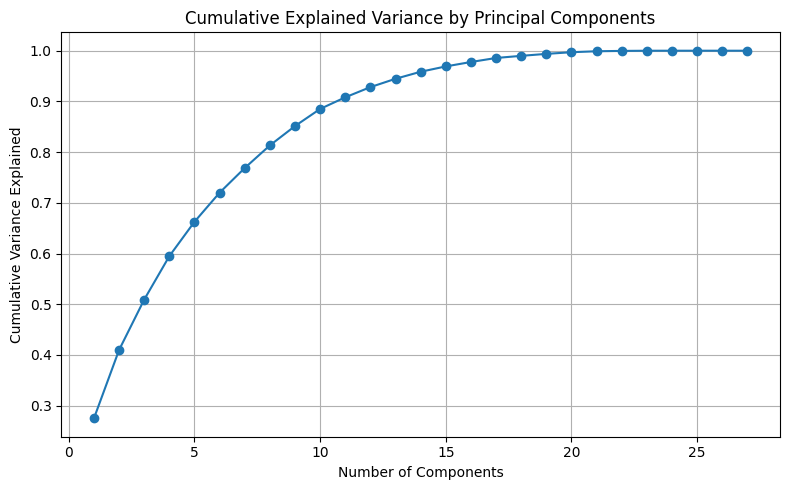

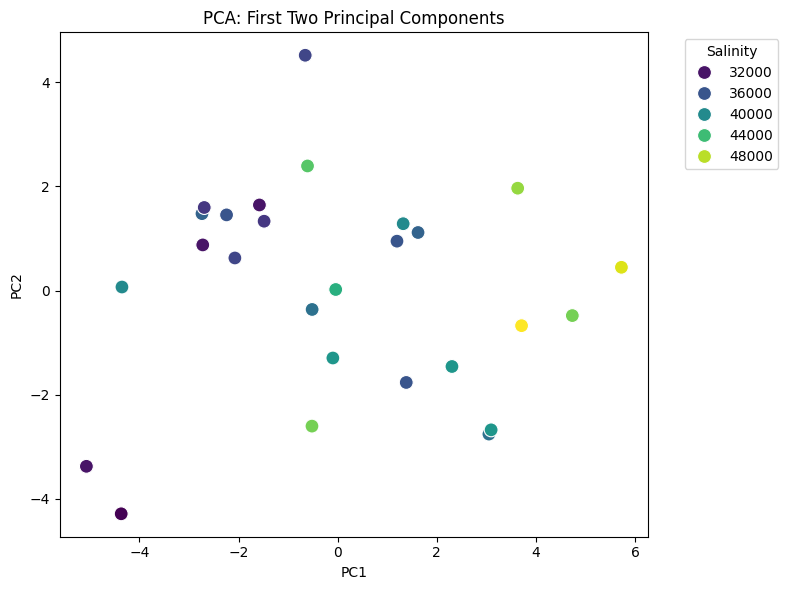


Top features from PC1 and PC2 combined: ['IR6+7ME', 'IIa_tprime', 'IR_prime6+7ME', 'Ib', 'IR6ME', 'IIa_prime', 'IIc', 'MBT_prime6Me', 'pH', 'Ic']

Model performance using top PC1 and PC2 features:
Mean Squared Error: 61907785.244
R-squared: -3.484


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# --------------------------
# Load Excel and Clean Data
# --------------------------
file_path = "/Users/Dasgu004/Library/CloudStorage/OneDrive-UniversiteitUtrecht/PostDoc/Projects/CN/Salinity_GDGT_Global.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1", header=0)
df.columns = df.columns.str.strip()

predictor_cols = [
    "SALINITY(mg/l)",
    "IIIa", "IIIa_prime", "IIIa_tprime", "IIIb", "IIIb_prime", "IIIc", "IIIc_prime",
    "IIa", "IIa_prime", "IIa_tprime", "IIb", "IIb_prime", "IIc", "IIc_prime",
    "Ia", "Ib", "Ic",
    "IR6ME", "IR7ME", "IR_prime6+7ME", "IR6+7ME",
    "MBT_prime 5Me", "MBT_prime6Me",
    "ACE", "ACE_prime",
    "MLWT", "pH", "DO", "TN", "OM", "C/N"
]
predictor_cols = [c for c in predictor_cols if c in df.columns]

df = df[predictor_cols].apply(pd.to_numeric, errors='coerce')
df = df.dropna(axis=0, how='any').dropna(axis=1, how='any')

y = df["SALINITY(mg/l)"]
X = df.drop(columns=["SALINITY(mg/l)"])

# --------------------------
# PCA Analysis
# --------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=[f"PC{i+1}" for i in range(X_pca.shape[1])])
pca_df["Salinity"] = y.values

# Explained variance
explained_var = pca.explained_variance_ratio_
print("\nExplained Variance per Component:")
for i, var in enumerate(explained_var[:10], 1):
    print(f"PC{i}: {var:.3f} ({var*100:.1f}%)")

print(f"\nCumulative variance explained by first 2 PCs: {explained_var[:2].sum()*100:.2f}%")
print(f"Cumulative variance explained by first 5 PCs: {explained_var[:5].sum()*100:.2f}%")

# Loadings
loading_matrix = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=[f"PC{i+1}" for i in range(X_pca.shape[1])]
)

print("\nTop 10 Loadings for PC1:")
print(loading_matrix["PC1"].abs().sort_values(ascending=False).head(10))
print("\nTop 10 Loadings for PC2:")
print(loading_matrix["PC2"].abs().sort_values(ascending=False).head(10))

# Cumulative variance plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_var) + 1), explained_var.cumsum(), marker='o')
plt.title("Cumulative Explained Variance by Principal Components")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance Explained")
plt.grid(True)
plt.tight_layout()
plt.show()

# PCA scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Salinity", palette="viridis", s=100)
plt.title("PCA: First Two Principal Components")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Salinity", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# --------------------------
# Regression on Top PCA Features
# --------------------------
top_pc1 = loading_matrix["PC1"].abs().sort_values(ascending=False).head(5).index.tolist()
top_pc2 = loading_matrix["PC2"].abs().sort_values(ascending=False).head(5).index.tolist()
top_features = list(set(top_pc1 + top_pc2))

print(f"\nTop features from PC1 and PC2 combined: {top_features}")

X_top = X[top_features]

X_train, X_test, y_train, y_test = train_test_split(X_top, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nModel performance using top PC1 and PC2 features:")
print(f"Mean Squared Error: {mse:.3f}")
print(f"R-squared: {r2:.3f}")



Number of PCs to reach ≥ 75% variance: 7
Selected features for XGBoost: ['IR6+7ME', 'TN', 'Ib', 'IIc', 'IIIa_prime', 'IIa_tprime', 'MBT_prime 5Me', 'IIb', 'IIIa_tprime', 'pH', 'IR7ME', 'Ia', 'IIIa', 'IR6ME', 'IIa_prime', 'IIb_prime', 'DO', 'ACE_prime', 'IR_prime6+7ME', 'IIa', 'IIc_prime', 'IIIc', 'IIIc_prime', 'MBT_prime6Me', 'Ic', 'MLWT', 'ACE']

XGBoost model performance:
Mean Squared Error: 33067371.992
R-squared: -1.395


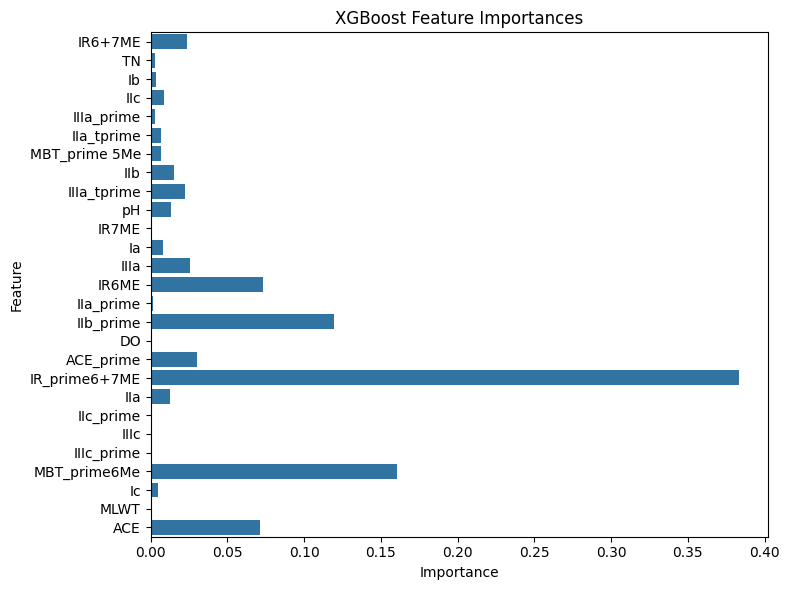

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

# --------------------------
# Load & Clean Data
# --------------------------
file_path = "/Users/Dasgu004/Library/CloudStorage/OneDrive-UniversiteitUtrecht/PostDoc/Projects/CN/Salinity_GDGT_Global.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1", header=0)
df.columns = df.columns.str.strip()

predictor_cols = [
    "SALINITY(mg/l)",
    "IIIa", "IIIa_prime", "IIIa_tprime", "IIIb", "IIIb_prime", "IIIc", "IIIc_prime",
    "IIa", "IIa_prime", "IIa_tprime", "IIb", "IIb_prime", "IIc", "IIc_prime",
    "Ia", "Ib", "Ic",
    "IR6ME", "IR7ME", "IR_prime6+7ME", "IR6+7ME",
    "MBT_prime 5Me", "MBT_prime6Me",
    "ACE", "ACE_prime",
    "MLWT", "pH", "DO", "TN", "OM", "C/N"
]
predictor_cols = [c for c in predictor_cols if c in df.columns]

df = df[predictor_cols].apply(pd.to_numeric, errors='coerce')
df = df.dropna(axis=0, how='any').dropna(axis=1, how='any')

y = df["SALINITY(mg/l)"]
X = df.drop(columns=["SALINITY(mg/l)"])

# --------------------------
# PCA
# --------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA()
X_pca = pca.fit_transform(X_scaled)
explained_var = pca.explained_variance_ratio_

# Determine number of PCs to reach ≥ 75% variance
cum_var = np.cumsum(explained_var)
n_components_75 = np.argmax(cum_var >= 0.75) + 1
print(f"\nNumber of PCs to reach ≥ 75% variance: {n_components_75}")

# --------------------------
# Extract features from top PCs
# --------------------------
loading_matrix = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=[f"PC{i+1}" for i in range(X_pca.shape[1])]
)

# Get top contributing features from each selected PC
selected_features = set()
for pc in range(n_components_75):
    top_feats = loading_matrix.iloc[:, pc].abs().sort_values(ascending=False).head(5).index.tolist()
    selected_features.update(top_feats)

selected_features = list(selected_features)
print(f"Selected features for XGBoost: {selected_features}")

# --------------------------
# XGBoost Model
# --------------------------
X_sel = X[selected_features]

X_train, X_test, y_train, y_test = train_test_split(X_sel, y, test_size=0.2, random_state=42)

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb_model.fit(X_train, y_train)
y_pred = xgb_model.predict(X_test)

# --------------------------
# Evaluation
# --------------------------
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nXGBoost model performance:")
print(f"Mean Squared Error: {mse:.3f}")
print(f"R-squared: {r2:.3f}")

# --------------------------
# Feature importance plot
# --------------------------
plt.figure(figsize=(8, 6))
sns.barplot(x=xgb_model.feature_importances_, y=selected_features)
plt.title("XGBoost Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


Fitting 5 folds for each of 2916 candidates, totalling 14580 fits

Best Parameters: {'colsample_bytree': 0.7, 'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 800, 'reg_alpha': 1, 'reg_lambda': 5, 'subsample': 0.7}
Optimized XGBoost Performance:
Mean Squared Error: 30294035.604
R-squared: -1.194


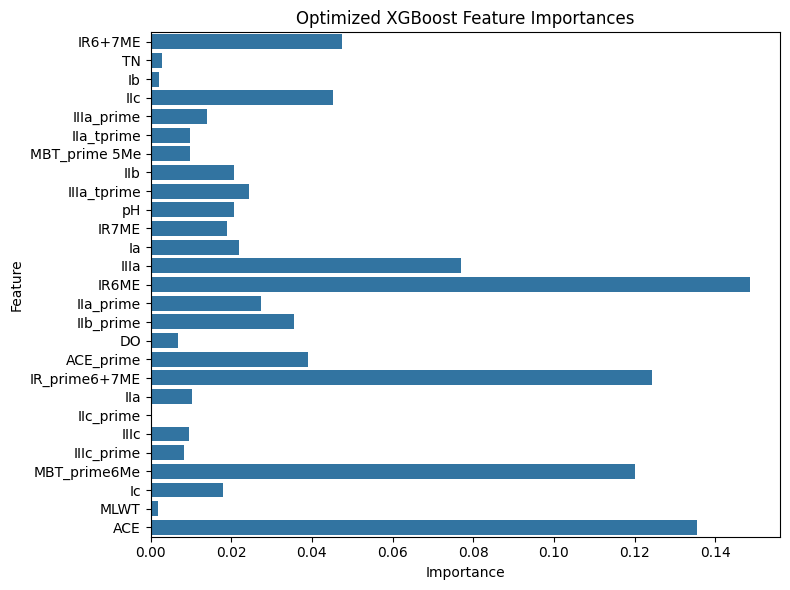

In [20]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor
import numpy as np

# --------------------------
# Use selected features from PCA
# --------------------------
X_sel = X[selected_features]

# --------------------------
# Split train/test
# --------------------------
X_train, X_test, y_train, y_test = train_test_split(X_sel, y, test_size=0.2, random_state=42)

# --------------------------
# Parameter grid for tuning
# --------------------------
param_grid = {
    "n_estimators": [200, 500, 800],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "reg_alpha": [0, 0.1, 1],
    "reg_lambda": [1, 5, 10]
}

xgb_model = XGBRegressor(random_state=42)

# --------------------------
# Grid search with 5-fold CV
# --------------------------
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring="r2",
    cv=5,
    verbose=1,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# --------------------------
# Best model & evaluation
# --------------------------
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nBest Parameters:", grid_search.best_params_)
print(f"Optimized XGBoost Performance:")
print(f"Mean Squared Error: {mse:.3f}")
print(f"R-squared: {r2:.3f}")

# --------------------------
# Feature importance
# --------------------------
plt.figure(figsize=(8, 6))
sns.barplot(x=best_model.feature_importances_, y=X_sel.columns)
plt.title("Optimized XGBoost Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


Top 10 features selected: ['ACE', 'IIb_prime', 'MBT_prime6Me', 'IR6ME', 'IIIa_tprime', 'IIIa', 'IIa_prime', 'IIb', 'C/N', 'DO']
Fitting 5 folds for each of 2187 candidates, totalling 10935 fits

Best Parameters: {'colsample_bytree': 0.7, 'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 800, 'reg_alpha': 0, 'reg_lambda': 1, 'subsample': 0.7}
Optimized XGBoost Performance:
Mean Squared Error: 13888685.260
R-squared: -0.006


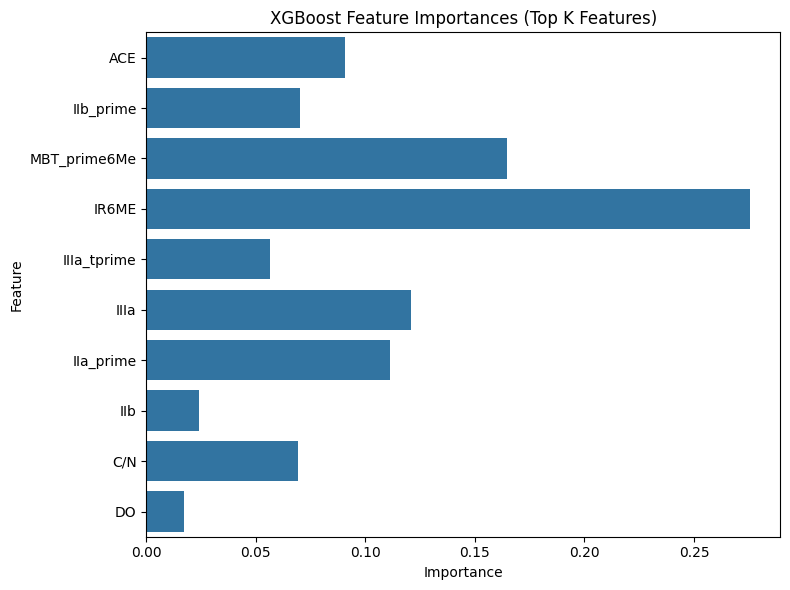

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

# --------------------------
# Load & Clean Data
# --------------------------
file_path = "/Users/Dasgu004/Library/CloudStorage/OneDrive-UniversiteitUtrecht/PostDoc/Projects/CN/Salinity_GDGT_Global.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1", header=0)
df.columns = df.columns.str.strip()

predictor_cols = [
    "SALINITY(mg/l)",
    "IIIa", "IIIa_prime", "IIIa_tprime", "IIIb", "IIIb_prime", "IIIc", "IIIc_prime",
    "IIa", "IIa_prime", "IIa_tprime", "IIb", "IIb_prime", "IIc", "IIc_prime",
    "Ia", "Ib", "Ic",
    "IR6ME", "IR7ME", "IR_prime6+7ME", "IR6+7ME",
    "MBT_prime 5Me", "MBT_prime6Me",
    "ACE", "ACE_prime",
    "MLWT", "pH", "DO", "TN", "OM", "C/N"
]
predictor_cols = [c for c in predictor_cols if c in df.columns]

df = df[predictor_cols].apply(pd.to_numeric, errors='coerce')
df = df.dropna(axis=0, how='any').dropna(axis=1, how='any')

y = df["SALINITY(mg/l)"]
X = df.drop(columns=["SALINITY(mg/l)"])

# --------------------------
# Step 1: Random Forest Feature Ranking
# --------------------------
rf = RandomForestRegressor(n_estimators=1000, random_state=42)
rf.fit(X, y)
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

# Choose top K features
k = 10  # you can adjust this
top_features = importances.head(k).index.tolist()
print(f"Top {k} features selected: {top_features}")

# --------------------------
# Step 2: Train/Test Split
# --------------------------
X_sel = X[top_features]
X_train, X_test, y_train, y_test = train_test_split(X_sel, y, test_size=0.2, random_state=42)

# --------------------------
# Step 3: Hyperparameter Tuning for XGBoost
# --------------------------
param_grid = {
    "n_estimators": [200, 500, 800],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "reg_alpha": [0, 0.1, 1],
    "reg_lambda": [1, 5, 10]
}

xgb_model = XGBRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring="r2",
    cv=5,
    verbose=1,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

# --------------------------
# Step 4: Model Evaluation
# --------------------------
y_pred = best_model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nBest Parameters:", grid_search.best_params_)
print(f"Optimized XGBoost Performance:")
print(f"Mean Squared Error: {mse:.3f}")
print(f"R-squared: {r2:.3f}")

# --------------------------
# Step 5: Feature Importance Plot
# --------------------------
plt.figure(figsize=(8, 6))
sns.barplot(x=best_model.feature_importances_, y=top_features)
plt.title("XGBoost Feature Importances (Top K Features)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


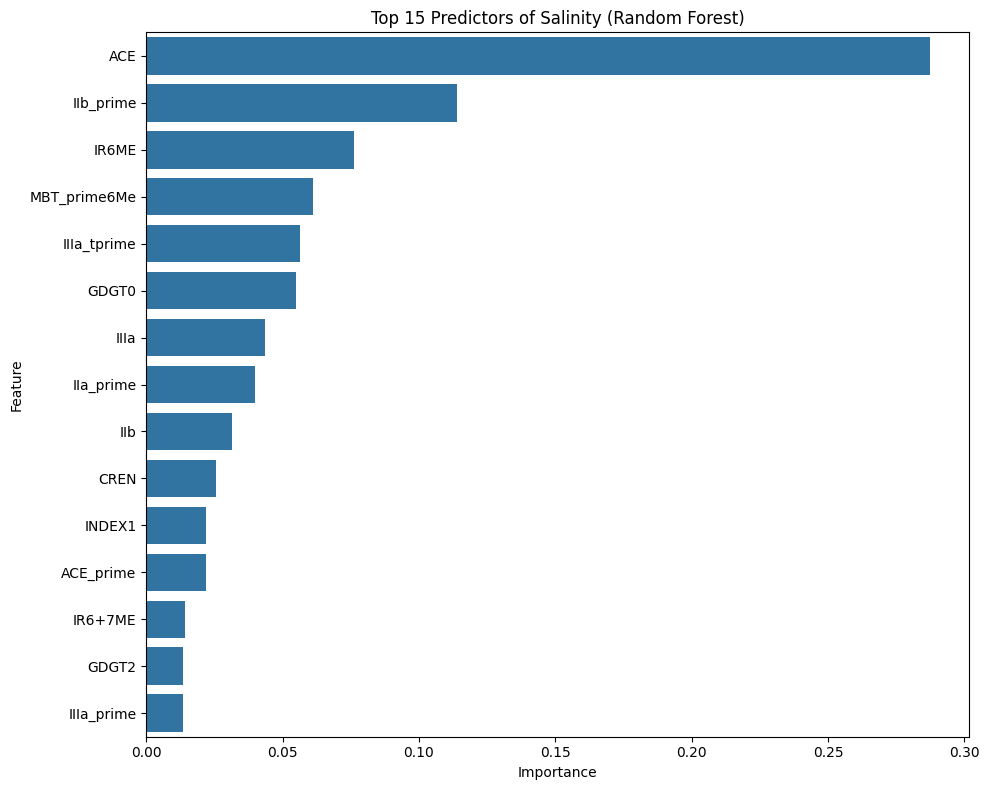

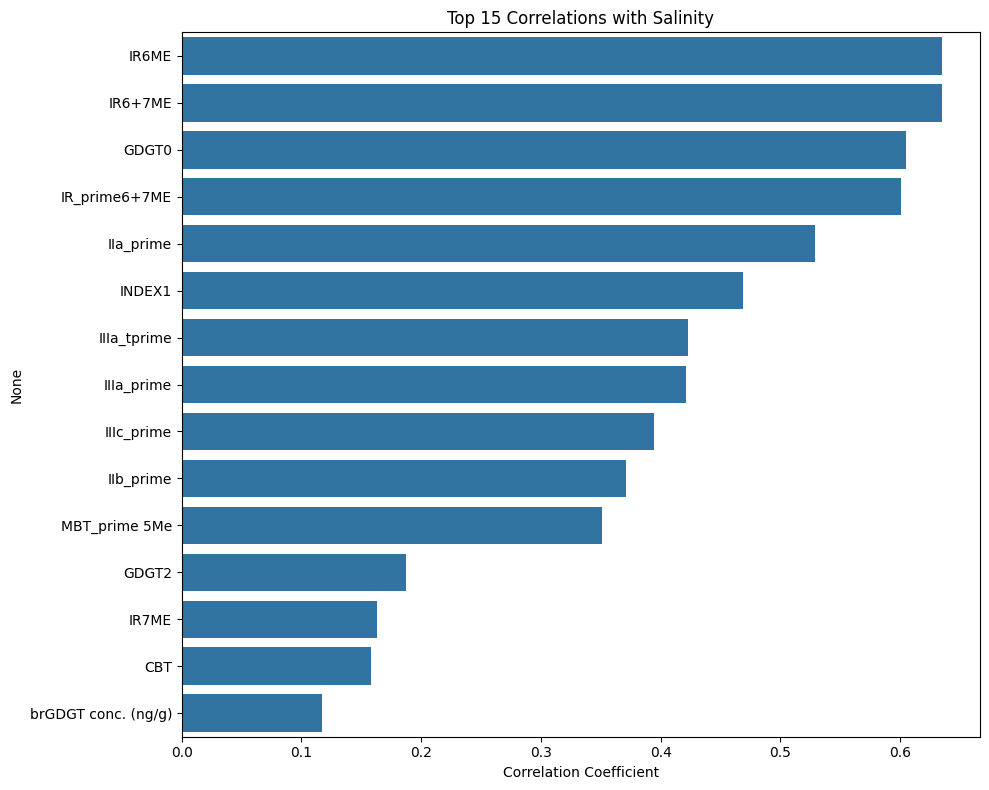

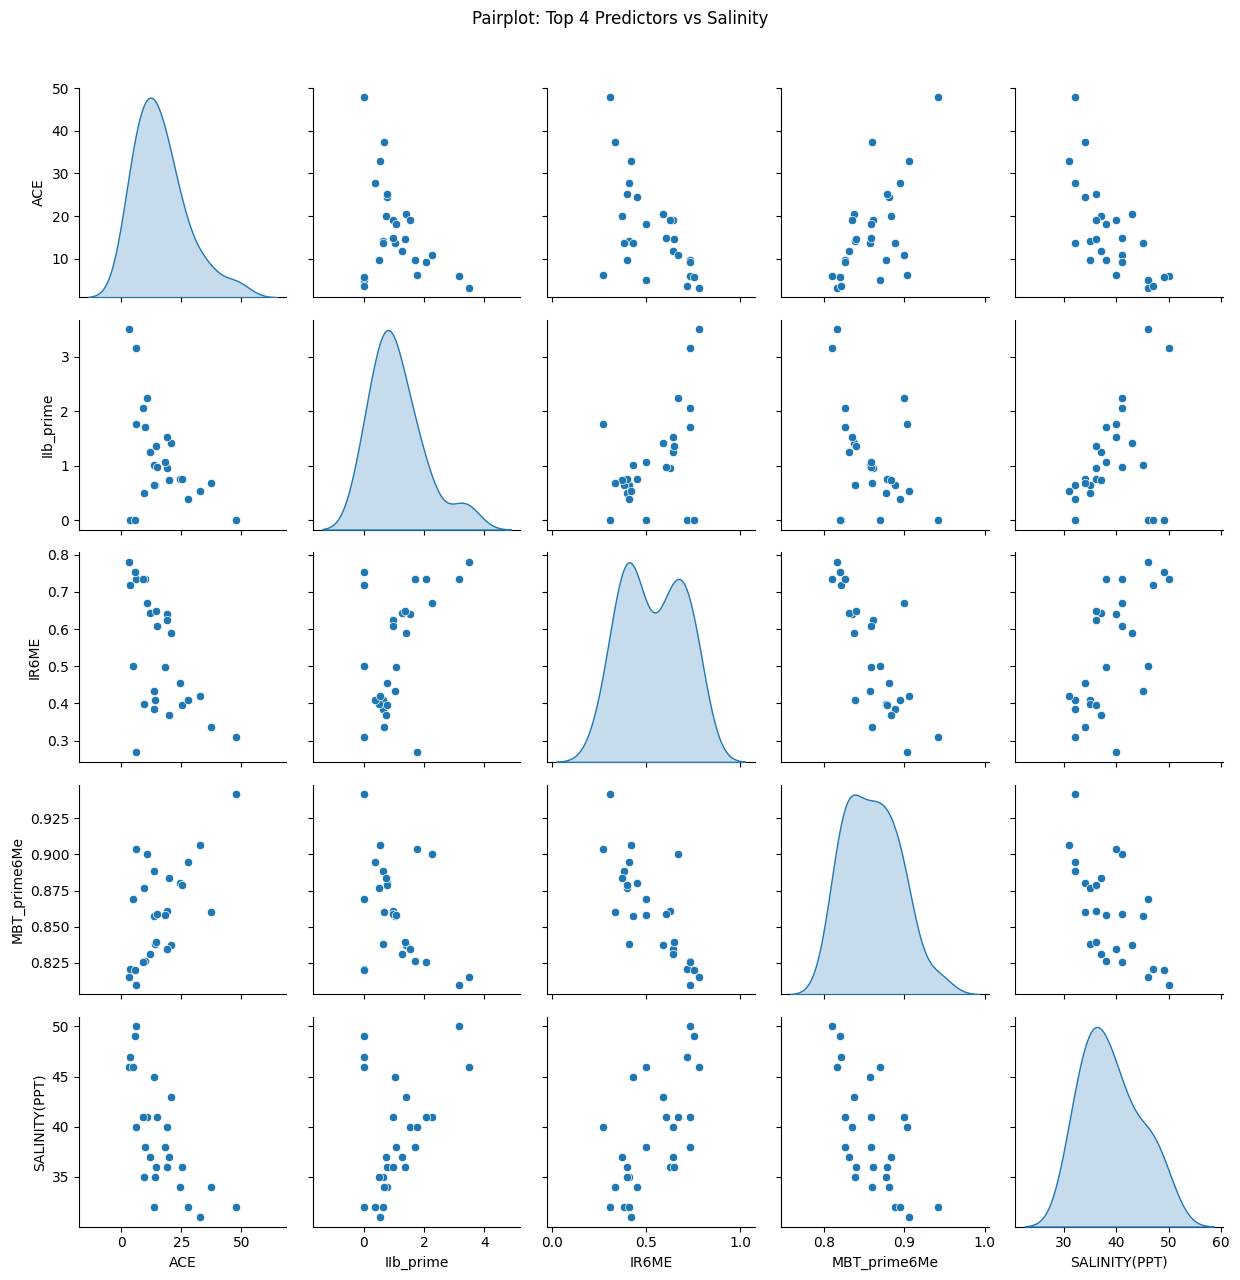

In [12]:
#Regional

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler

# Load the Excel file
file_path = "/Users/Dasgu004/Library/CloudStorage/OneDrive-UniversiteitUtrecht/PostDoc/Projects/CN/Pulicat_GDGT_python.xlsx"  # Replace with your actual path
df = pd.read_excel(file_path, sheet_name="Sheet1", header=1)

# Clean column names
df.columns = df.columns.str.strip()

# Drop rows with missing salinity
df = df.dropna(subset=["SALINITY(PPT)"])

# Target variable
y = df["SALINITY(PPT)"]

# --------------------------
# Select predictor columns
# --------------------------

# Manually define column ranges based on your screenshot
br_isomers = df.loc[:, "IIIa":"brGDGT conc. (ng/g)"]
iso_isomers = df.loc[:, "Archaeol":"CREN_prime"]
br_indices = df.loc[:, "BIT":"MBT_prime6Me"]
iso_indices = df.loc[:, ["ACE", "ACE_prime"]]

# Combine all predictors
X = pd.concat([br_isomers, iso_isomers, br_indices, iso_indices], axis=1)

# Drop any non-numeric or all-NaN columns
X = X.select_dtypes(include="number").dropna(axis=1, how="all")

# Standardize for ML
X_scaled = StandardScaler().fit_transform(X)

# --------------------------
# Random Forest for Feature Importance
# --------------------------
rf = RandomForestRegressor(n_estimators=500, random_state=42)
rf.fit(X_scaled, y)
importances = rf.feature_importances_

# Feature importance plot
importance_df = pd.DataFrame({"Feature": X.columns, "Importance": importances})
importance_df = importance_df.sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=importance_df.head(15), x="Importance", y="Feature")
plt.title("Top 15 Predictors of Salinity (Random Forest)")
plt.tight_layout()
plt.show()

# --------------------------
# Correlation matrix
# --------------------------
corr = X.corrwith(y).sort_values(ascending=False)
plt.figure(figsize=(10, 8))
sns.barplot(x=corr.head(15), y=corr.head(15).index)
plt.title("Top 15 Correlations with Salinity")
plt.xlabel("Correlation Coefficient")
plt.tight_layout()
plt.show()

# --------------------------
# Pairplot: Top 4 variables
# --------------------------
top_vars = importance_df["Feature"].head(4).tolist()
sns.pairplot(df[top_vars + ["SALINITY(PPT)"]], diag_kind="kde")
plt.suptitle("Pairplot: Top 4 Predictors vs Salinity", y=1.02)
plt.tight_layout()
plt.show()


Top 10 features selected: ['ACE', 'IIb_prime', 'IR6ME', 'GDGT0', 'MBT_prime6Me', 'IIIa_tprime', 'IIIa', 'IIa_prime', 'INDEX1', 'IIb']
Fitting 5 folds for each of 2187 candidates, totalling 10935 fits

Best Parameters: {'colsample_bytree': 0.7, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 800, 'reg_alpha': 0, 'reg_lambda': 1, 'subsample': 0.7}
Optimized XGBoost Performance:
Mean Squared Error: 17.654
R-squared: -0.279


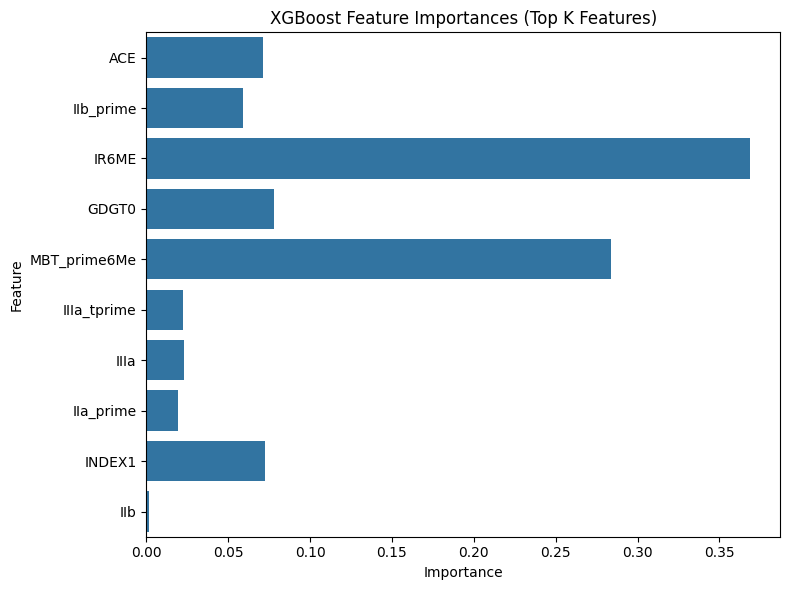

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

# --------------------------
# Load & Clean Data
# --------------------------
file_path = "/Users/Dasgu004/Library/CloudStorage/OneDrive-UniversiteitUtrecht/PostDoc/Projects/CN/Pulicat_GDGT_python.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1", header=1)
df.columns = df.columns.str.strip()

predictor_cols = [
    "SALINITY(PPT)", "IIIa", "IIIa_prime", "IIIa_tprime", "IIIb", "IIIb_prime", "IIIc", "IIIc_prime",
    "IIa", "IIa_prime", "IIa_tprime", "IIb", "IIb_prime", "IIc", "IIc_prime",
    "Ia", "Ib", "Ic", "brGDGT conc. (ng/g)",
    "Archaeol", "GDGT0", "GDGT1", "GDGT2", "GDGT3", "CREN", "CREN_prime",
    "BIT", "CBT", "CBT_prime", "MBT_prime", "CBT 5Me",
    "IR6ME", "IR7ME", "IR_prime6+7ME", "IR6+7ME", "INDEX1", "MBT_prime 5Me", "MBT_prime6Me",
    "ACE", "ACE_prime", "MLWT", "Sedi pH", "DO", "TN", "OM", "C/N"
]

predictor_cols = [c for c in predictor_cols if c in df.columns]

df = df[predictor_cols].apply(pd.to_numeric, errors='coerce')
df = df.dropna(axis=0, how='any').dropna(axis=1, how='any')

y = df["SALINITY(PPT)"]
X = df.drop(columns=["SALINITY(PPT)"])

# --------------------------
# Step 1: Random Forest Feature Ranking
# --------------------------
rf = RandomForestRegressor(n_estimators=1000, random_state=42)
rf.fit(X, y)
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

# Choose top K features
k = 10  # you can adjust this
top_features = importances.head(k).index.tolist()
print(f"Top {k} features selected: {top_features}")

# --------------------------
# Step 2: Train/Test Split
# --------------------------
X_sel = X[top_features]
X_train, X_test, y_train, y_test = train_test_split(X_sel, y, test_size=0.2, random_state=42)

# --------------------------
# Step 3: Hyperparameter Tuning for XGBoost
# --------------------------
param_grid = {
    "n_estimators": [200, 500, 800],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "reg_alpha": [0, 0.1, 1],
    "reg_lambda": [1, 5, 10]
}

xgb_model = XGBRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring="r2",
    cv=5,
    verbose=1,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

# --------------------------
# Step 4: Model Evaluation
# --------------------------
y_pred = best_model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nBest Parameters:", grid_search.best_params_)
print(f"Optimized XGBoost Performance:")
print(f"Mean Squared Error: {mse:.3f}")
print(f"R-squared: {r2:.3f}")

# --------------------------
# Step 5: Feature Importance Plot
# --------------------------
plt.figure(figsize=(8, 6))
sns.barplot(x=best_model.feature_importances_, y=top_features)
plt.title("XGBoost Feature Importances (Top K Features)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()



Explained Variance per Component:
PC1: 0.244 (24.4%)
PC2: 0.141 (14.1%)
PC3: 0.119 (11.9%)
PC4: 0.103 (10.3%)
PC5: 0.076 (7.6%)
PC6: 0.068 (6.8%)
PC7: 0.052 (5.2%)
PC8: 0.037 (3.7%)
PC9: 0.031 (3.1%)
PC10: 0.026 (2.6%)

Cumulative variance explained by first 2 PCs: 38.42%
Cumulative variance explained by first 5 PCs: 68.22%

Top 10 Loadings for PC1:
IR6ME            0.318753
IR6+7ME          0.315766
IR_prime6+7ME    0.298346
MBT_prime6Me     0.273530
IIa              0.262958
IIa_prime        0.260686
INDEX1           0.253414
MBT_prime 5Me    0.247391
ACE              0.214621
CBT              0.208597
Name: PC1, dtype: float64

Top 10 Loadings for PC2:
Ic            0.356892
CBT 5Me       0.342994
Ib            0.319590
CBT_prime     0.300110
CREN_prime    0.286009
GDGT3         0.275105
Ia            0.264854
IIIc          0.222264
GDGT2         0.215213
CBT           0.185936
Name: PC2, dtype: float64


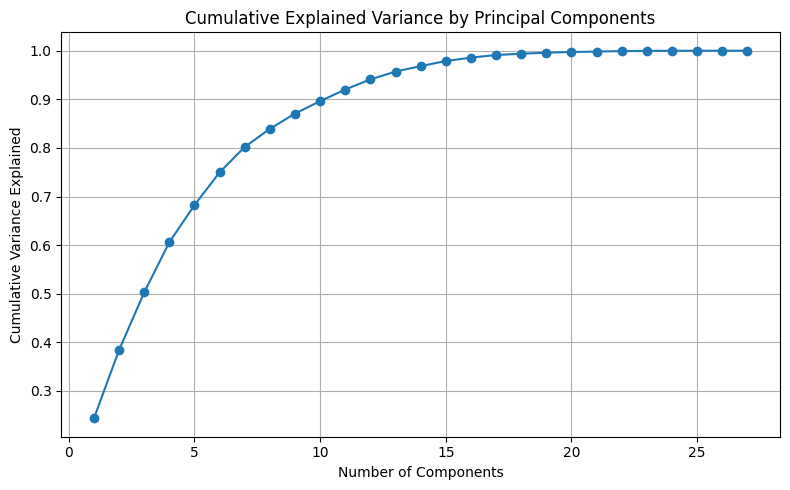

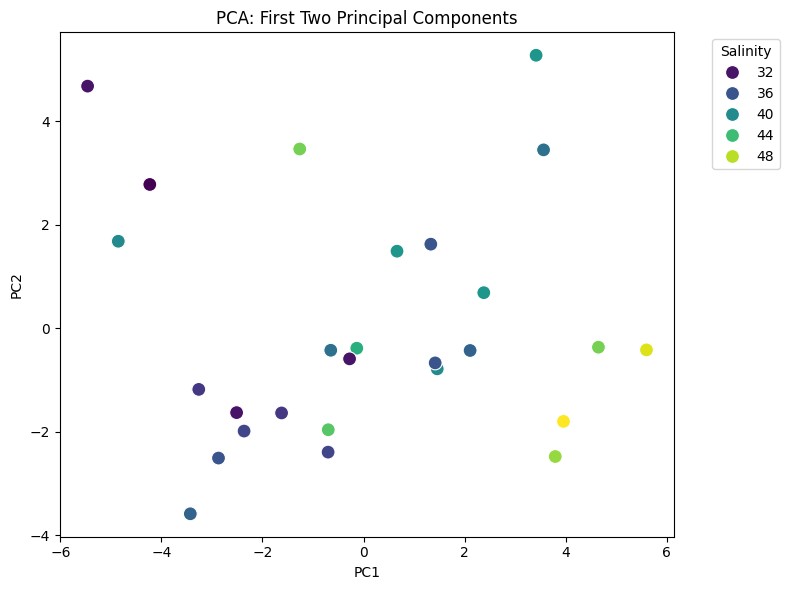

In [2]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Run PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Create DataFrame with PCA results
pca_df = pd.DataFrame(X_pca, columns=[f"PC{i+1}" for i in range(X_pca.shape[1])])
pca_df["Salinity"] = y.values

# -----------------------------
# 1. Print explained variance
# -----------------------------
explained_var = pca.explained_variance_ratio_
print("\nExplained Variance per Component:")
for i, var in enumerate(explained_var[:10], 1):
    print(f"PC{i}: {var:.3f} ({var*100:.1f}%)")

print(f"\nCumulative variance explained by first 2 PCs: {explained_var[:2].sum()*100:.2f}%")
print(f"Cumulative variance explained by first 5 PCs: {explained_var[:5].sum()*100:.2f}%")

# -----------------------------
# 2. Feature loadings (PC1/PC2)
# -----------------------------
loading_matrix = pd.DataFrame(pca.components_.T, 
                              index=X.columns, 
                              columns=[f"PC{i+1}" for i in range(X_pca.shape[1])])

# Top contributors to PC1 and PC2
print("\nTop 10 Loadings for PC1:")
print(loading_matrix["PC1"].abs().sort_values(ascending=False).head(10))

print("\nTop 10 Loadings for PC2:")
print(loading_matrix["PC2"].abs().sort_values(ascending=False).head(10))

# -----------------------------
# 3. Cumulative Variance Plot
# -----------------------------
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_var) + 1), explained_var.cumsum(), marker='o')
plt.title("Cumulative Explained Variance by Principal Components")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance Explained")
plt.grid(True)
plt.tight_layout()
plt.show()

# -----------------------------
# 4. PCA Scatter Plot (PC1 vs PC2)
# -----------------------------
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Salinity", palette="viridis", s=100)
plt.title("PCA: First Two Principal Components")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Salinity", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Step 1: Get top features based on absolute loadings in PC1 and PC2
top_pc1 = loading_matrix["PC1"].abs().sort_values(ascending=False).head(5).index.tolist()
top_pc2 = loading_matrix["PC2"].abs().sort_values(ascending=False).head(5).index.tolist()

# Combine top features from both PCs without duplicates
top_features = list(set(top_pc1 + top_pc2))
print(f"Top features from PC1 and PC2 combined: {top_features}")

# Step 2: Select these features from the original (unscaled) dataset
X_top = X[top_features]

# Step 3: Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X_top, y, test_size=0.2, random_state=42)

# Step 4: Train a regression model (Linear Regression as example)
model = LinearRegression()
model.fit(X_train, y_train)

# Step 5: Predict on test set
y_pred = model.predict(X_test)

# Step 6: Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Model performance using top PC1 and PC2 features:")
print(f"Mean Squared Error: {mse:.3f}")
print(f"R-squared: {r2:.3f}")


Top features from PC1 and PC2 combined: ['IR6+7ME', 'IR_prime6+7ME', 'IIa', 'Ib', 'CREN_prime', 'CBT_prime', 'IR6ME', 'CBT 5Me', 'MBT_prime6Me', 'Ic']
Model performance using top PC1 and PC2 features:
Mean Squared Error: 45.719
R-squared: -2.312


## 1. **Explained Variance**

| PC  | Variance (%) | Cumulative (%) |
| --- | ------------ | -------------- |
| PC1 | 24.4%        |                |
| PC2 | 14.1%        | **38.4%**      |
| PC3 | 11.9%        |                |
| PC4 | 10.3%        |                |
| PC5 | 7.6%         | **68.2%**      |

> **Interpretation**: The first 5 principal components explain \~68% of the total variance — meaning you’ve captured most of the signal using only 5 dimensions, which is great for simplification or clustering.

---

## 2. **Top Loadings for PC1**

These are the features that most influence **PC1**, which explains 24.4% of the variance.

| Feature  | Loading |
| -------- | ------- |
| IR6ME    | 0.319   |
| IR6+7ME  | 0.316   |
| IR′6+7ME | 0.298   |
| MBT′6Me  | 0.274   |
| IIa      | 0.263   |
| IIa′     | 0.261   |
| INDEX1   | 0.253   |
| MBT′5Me  | 0.247   |
| ACE      | 0.215   |
| CBT      | 0.209   |

> **Interpretation**: PC1 is **heavily influenced by branched GDGT-derived indices** (especially **IR6ME**, **MBT′**, **CBT**, and **IIa** isomers). These variables likely form a cluster of correlated environmental signals — e.g., temperature/pH/salinity gradients.

---

## 3. **Top Loadings for PC2**

These dominate **PC2**, which explains 14.1% of variance.

| Feature | Loading |
| ------- | ------- |
| Ic      | 0.357   |
| CBT 5Me | 0.343   |
| Ib      | 0.320   |
| CBT′    | 0.300   |
| CREN′   | 0.286   |
| GDGT3   | 0.275   |
| Ia      | 0.265   |
| IIIc    | 0.222   |
| GDGT2   | 0.215   |
| CBT     | 0.186   |

> **Interpretation**: PC2 is more **mixed**, including:

* **BrGDGT isomers** (Ic, Ib, Ia)
* **Iso-GDGTs** (CREN′, GDGT3, GDGT2)
* Again, **CBT-type indices** show up — suggesting they play a role across multiple variance axes.

---

## Summary of Insights:

* **PC1 is dominated by IR and MBT-related indices** → possibly reflecting a gradient (e.g., pH, temperature) that correlates with salinity.
* **PC2 captures variability in both Br and Iso GDGTs** → may represent a **separate ecological axis** (e.g., microbial community or depth effect).
* **Br indices (especially IR and MBT) and isomers (IIa, Ic, Ib)** are **strong structural components** in your dataset.


In [4]:
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import cross_val_score

# Expand features: take top 5 from PC1-PC5 (or all features if manageable)
top_pc3 = loading_matrix["PC3"].abs().sort_values(ascending=False).head(5).index.tolist()
top_pc4 = loading_matrix["PC4"].abs().sort_values(ascending=False).head(5).index.tolist()
top_pc5 = loading_matrix["PC5"].abs().sort_values(ascending=False).head(5).index.tolist()

top_features_extended = list(set(top_features + top_pc3 + top_pc4 + top_pc5))
X_extended = X[top_features_extended]

# Ridge regression with built-in alpha tuning
alphas = [0.1, 1.0, 10.0, 100.0]
ridge_cv = RidgeCV(alphas=alphas, cv=5)
ridge_cv.fit(X_extended, y)

# Cross-validation score
cv_scores = cross_val_score(ridge_cv, X_extended, y, cv=5, scoring='r2')

print(f"Best alpha: {ridge_cv.alpha_}")
print(f"Mean CV R^2: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

# Evaluate on test set split as before
X_train, X_test, y_train, y_test = train_test_split(X_extended, y, test_size=0.2, random_state=42)
ridge_cv.fit(X_train, y_train)
y_pred = ridge_cv.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Test set MSE: {mse:.3f}")
print(f"Test set R^2: {r2:.3f}")


Best alpha: 0.1
Mean CV R^2: -3.799 ± 7.212
Test set MSE: 13.342
Test set R^2: 0.034


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# 1. Select features (top from PCs 1-5)
top_pc1 = loading_matrix["PC1"].abs().sort_values(ascending=False).head(5).index.tolist()
top_pc2 = loading_matrix["PC2"].abs().sort_values(ascending=False).head(5).index.tolist()
top_pc3 = loading_matrix["PC3"].abs().sort_values(ascending=False).head(5).index.tolist()
top_pc4 = loading_matrix["PC4"].abs().sort_values(ascending=False).head(5).index.tolist()
top_pc5 = loading_matrix["PC5"].abs().sort_values(ascending=False).head(5).index.tolist()

top_features = list(set(top_pc1 + top_pc2 + top_pc3 + top_pc4 + top_pc5))

X_top = X[top_features]

# Split for Random Forest
X_train, X_test, y_train, y_test = train_test_split(X_top, y, test_size=0.2, random_state=42)

# ---- Random Forest Regressor ----
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Random Forest Regression Results:")
print(f"Test MSE: {mean_squared_error(y_test, y_pred_rf):.3f}")
print(f"Test R^2: {r2_score(y_test, y_pred_rf):.3f}")
print()

# ---- PCA + Linear Regression ----

# Standardize full original dataset before PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA transform to 5 components
pca = PCA(n_components=5)
X_pca = pca.fit_transform(X_scaled)

# Split PCA data
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(X_pca, y, test_size=0.2, random_state=42)

# Linear Regression on PCA components
lr_pca = LinearRegression()
lr_pca.fit(X_train_pca, y_train_pca)
y_pred_pca = lr_pca.predict(X_test_pca)

print("PCA-based Linear Regression Results:")
print(f"Test MSE: {mean_squared_error(y_test_pca, y_pred_pca):.3f}")
print(f"Test R^2: {r2_score(y_test_pca, y_pred_pca):.3f}")


Random Forest Regression Results:
Test MSE: 21.255
Test R^2: -0.540

PCA-based Linear Regression Results:
Test MSE: 17.605
Test R^2: -0.275


In [6]:
# Check skewness
print(f"Original target skewness: {y.skew():.3f}")

# Add constant to avoid log(0)
y_log = np.log1p(y - y.min() + 1)

print(f"Log-transformed target skewness: {pd.Series(y_log).skew():.3f}")

# Then re-run a simple model on y_log (e.g. linear regression on top features)

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_top, y_log, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Linear regression on log-transformed target:")
print(f"Test R^2: {r2_score(y_test, y_pred):.3f}")


Original target skewness: 0.482
Log-transformed target skewness: -0.557
Linear regression on log-transformed target:
Test R^2: -5.548


In [7]:
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# --------------------------
# Step 1: Select only index variables (no isomers)
# --------------------------
index_df = pd.concat([br_indices, iso_indices], axis=1)
index_df = index_df.select_dtypes(include="number").dropna(axis=1, how="any")

# --------------------------
# Step 2: Standardize for PCA
# --------------------------
scaler = StandardScaler()
index_scaled = scaler.fit_transform(index_df)

# --------------------------
# Step 3: Run PCA
# --------------------------
pca = PCA()
pca.fit(index_scaled)
loadings = pd.DataFrame(pca.components_.T, columns=[f"PC{i+1}" for i in range(pca.n_components_)],
                        index=index_df.columns)

# --------------------------
# Step 4: Top loadings for PC1 and PC2
# --------------------------
top_pc1 = loadings["PC1"].abs().sort_values(ascending=False).head(5).index.tolist()
top_pc2 = loadings["PC2"].abs().sort_values(ascending=False).head(5).index.tolist()

# Combine unique features from both
top_features = list(set(top_pc1 + top_pc2))
print("Top features from PC1 and PC2:", top_features)

# --------------------------
# Step 5: Select these from original (unscaled) data
# --------------------------
X_top = index_df[top_features]

# --------------------------
# Step 6: Train/test split
# --------------------------
X_train, X_test, y_train, y_test = train_test_split(X_top, y, test_size=0.2, random_state=42)

# --------------------------
# Step 7: Gradient Boosting Regressor
# --------------------------
gbr = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)
gbr.fit(X_train, y_train)
y_pred = gbr.predict(X_test)

# --------------------------
# Step 8: Evaluate model
# --------------------------
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nGradient Boosting Regressor (Top PCA Loadings from Indices):")
print(f"Test MSE: {mse:.3f}")
print(f"Test R²: {r2:.3f}")


Top features from PC1 and PC2: ['ACE_prime', 'IR6+7ME', 'MBT_prime 5Me', 'IR_prime6+7ME', 'CBT', 'MBT_prime', 'CBT_prime', 'IR6ME', 'CBT 5Me', 'MBT_prime6Me']

Gradient Boosting Regressor (Top PCA Loadings from Indices):
Test MSE: 43.838
Test R²: -2.175


Top features from PC1 and PC2: ['IR6+7ME', 'MBT_prime 5Me', 'IR_prime6+7ME', 'CBT', 'MBT_prime', 'IR6ME', 'CBT 5Me', 'Sedi pH', 'MBT_prime6Me', 'MLWT']

Gradient Boosting Regressor (Indices + Environmental Features):
Test MSE: 47.364
Test R²: -2.431


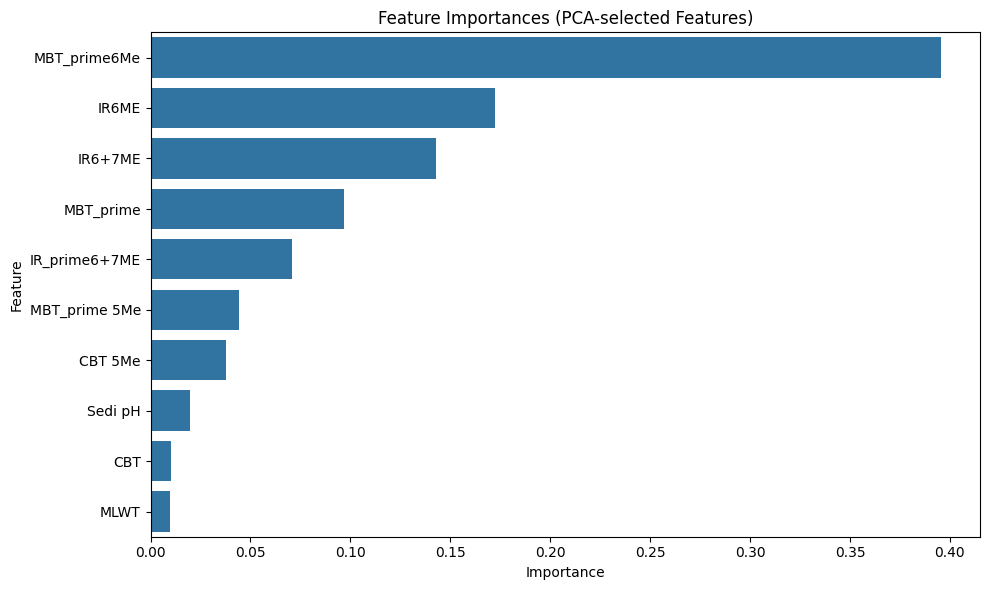

         Feature  Importance
8   MBT_prime6Me    0.395293
5          IR6ME    0.172409
0        IR6+7ME    0.142958
4      MBT_prime    0.096887
2  IR_prime6+7ME    0.070867
1  MBT_prime 5Me    0.044170
6        CBT 5Me    0.037633
7        Sedi pH    0.019908
3            CBT    0.010062
9           MLWT    0.009812


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# --------------------------
# Step 1: Select columns
# --------------------------
gdgt_indices = [
    "BIT", "CBT", "CBT_prime", "MBT_prime", "CBT 5Me",
    "IR6ME", "IR7ME", "IR_prime6+7ME", "IR6+7ME", "INDEX1",
    "MBT_prime 5Me", "MBT_prime6Me", "ACE", "ACE_prime"
]

env_params = ["MLWT", "Sedi pH", "DO", "TN", "OM", "C/N"]

# Target
y = df["SALINITY(PPT)"]

# Drop rows with missing target
df_clean = df.dropna(subset=["SALINITY(PPT)"])

# Extract features
X_pca_raw = df_clean[gdgt_indices + env_params].copy()
X_pca_raw = X_pca_raw.select_dtypes(include="number").dropna()

# Align y
y = y.loc[X_pca_raw.index]

# --------------------------
# Step 2: PCA
# --------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca_raw)

pca = PCA()
pca.fit(X_scaled)

loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)],
    index=X_pca_raw.columns
)

# --------------------------
# Step 3: Select top loadings from PC1 & PC2
# --------------------------
top_pc1 = loadings["PC1"].abs().sort_values(ascending=False).head(5).index.tolist()
top_pc2 = loadings["PC2"].abs().sort_values(ascending=False).head(5).index.tolist()
top_features = list(set(top_pc1 + top_pc2))

print("Top features from PC1 and PC2:", top_features)

# --------------------------
# Step 4: Gradient Boosting on selected features
# --------------------------
X_selected = X_pca_raw[top_features]
X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.2, random_state=42)

gbr = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)
gbr.fit(X_train, y_train)
y_pred = gbr.predict(X_test)

# --------------------------
# Step 5: Evaluate
# --------------------------
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nGradient Boosting Regressor (Indices + Environmental Features):")
print(f"Test MSE: {mse:.3f}")
print(f"Test R²: {r2:.3f}")

# --------------------------
# Optional: Feature importance plot
# --------------------------
importances = gbr.feature_importances_
feat_df = pd.DataFrame({"Feature": X_selected.columns, "Importance": importances})
feat_df = feat_df.sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(data=feat_df, x="Importance", y="Feature")
plt.title("Feature Importances (PCA-selected Features)")
plt.tight_layout()
plt.show()
print(feat_df)
